# LAB 10 — K-Means Clustering
## Student Information
Name:Anisa Sachdev
Student ID: 023-24-0222
Section:G
GitHub:
Kaggle:
Dataset: Mall Customers (Kaggle) + Wine (UCI)
Dataset Source: https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python and https://archive.ics.uci.edu/dataset/109/wine

> Place `Mall_Customers.csv` next to this notebook. `SEED = 42` everywhere. All numbers quoted in the answers come from running this notebook; re-run it and check them against your own output before submitting.

## Part 0 — Setup and First Look

In [1]:
from google.colab import files
uploaded = files.upload()

Saving Mall_Customers.csv to Mall_Customers.csv


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.datasets import load_wine
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
warnings.filterwarnings("ignore")
SEED = 42
pd.set_option("display.width", 200)

### Task 0.1 — Load and check the data

In [3]:
df = pd.read_csv("Mall_Customers.csv")
df = df.rename(columns={"Annual Income (k$)": "Income", "Spending Score (1-100)": "Spending"})
print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print(df["Gender"].value_counts())
df[["Age", "Income", "Spending"]].describe().round(2)

Shape: (200, 5)
Missing values: 0
Duplicate rows: 0
Gender
Female    112
Male       88
Name: count, dtype: int64


,Age,Income,Spending
count,200.00,200.00,200.00
mean,38.85,60.56,50.20
std,13.97,26.26,25.82
min,18.00,15.00,1.00
25%,28.75,41.50,34.75
50%,36.00,61.50,50.00
75%,49.00,78.00,73.00
max,70.00,137.00,99.00


**Interpretation.** 200 customers, 5 columns, no missing values, no duplicates; 112 Female / 88 Male. Age averages 38.9 (18–70), Income 60.6 k$ (15–137), Spending 50.2 (1–99). Income and Spending have similar spreads (std 26.3 and 25.8), which is why they can be clustered together even without scaling.

### Task 0.2 — Look at the data before clustering

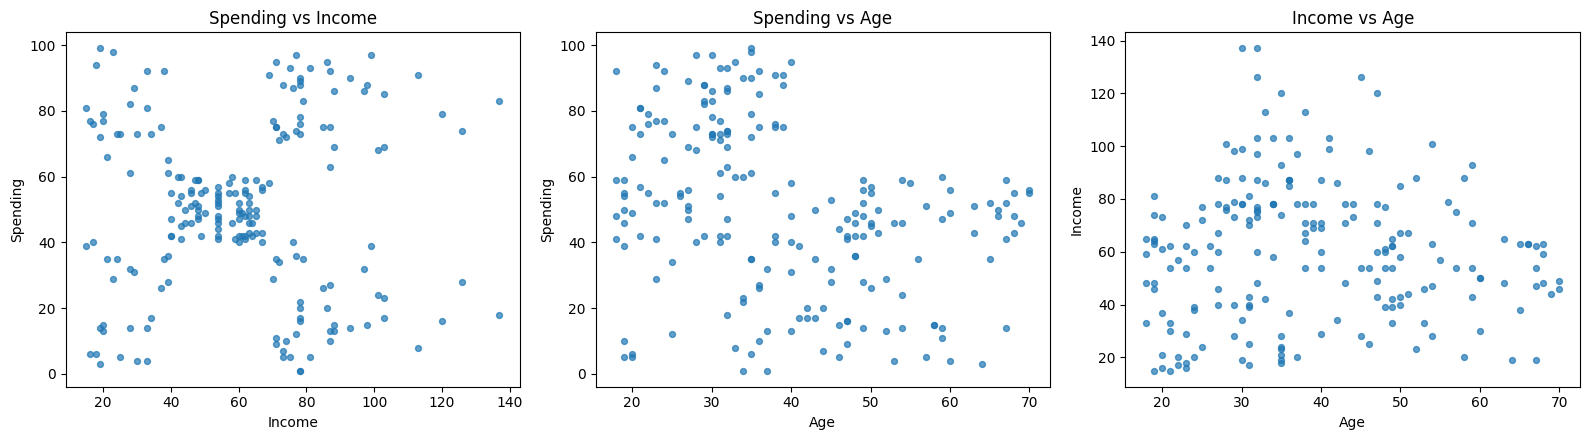

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, (x, y) in zip(ax, [("Income", "Spending"), ("Age", "Spending"), ("Age", "Income")]):
    a.scatter(df[x], df[y], s=18, alpha=.7); a.set_xlabel(x); a.set_ylabel(y); a.set_title(f"{y} vs {x}")
plt.tight_layout(); plt.show()

**Interpretation.** The left plot (Spending vs Income) shows a clear block structure; the other two look like one cloud.

**(a)** Spending vs Income: **5 groups** by eye: one dense centre block (Income ≈ 40–70, Spending ≈ 40–60) and four corners (low/low, low/high, high/low, high/high). Spending vs Age: no clean groups; I can see at most 2 loose regions (younger customers, under ~40, reach Spending 60–99; older ones sit mostly below 60). Income vs Age: **no visible groups**, one wide cloud. So Spending vs Income shows the groups most clearly.

**(b)** There is no true label column to compare against, so accuracy is undefined; and there is nothing to predict on a test set. The algorithm sees all points and only groups them. A clustering has to be judged by internal measures (inertia, silhouette), by stability, and by whether the groups make sense to a business.

## Part 1 — K-Means From Scratch

### Task 1.1 — Lecture Example 1 in code (one feature)

In [5]:
x = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25], dtype=float)
m = np.array([4., 11.])
it = 0
while True:
    it += 1
    dist = np.abs(x[:, None] - m[None, :])          # (9, 2)
    lab = dist.argmin(axis=1)
    new_m = np.array([x[lab == k].mean() for k in range(2)])
    print(f"Iter {it}: C1={x[lab==0].tolist()}  C2={x[lab==1].tolist()}  new centroids={new_m.tolist()}")
    if np.allclose(new_m, m): break
    m = new_m
inertia = sum(((x[lab == k] - m[k]) ** 2).sum() for k in range(2))
print("Final centroids:", m, "| inertia:", inertia)

Iter 1: C1=[2.0, 4.0, 3.0]  C2=[10.0, 12.0, 20.0, 30.0, 11.0, 25.0]  new centroids=[3.0, 18.0]
Iter 2: C1=[2.0, 4.0, 10.0, 3.0]  C2=[12.0, 20.0, 30.0, 11.0, 25.0]  new centroids=[4.75, 19.6]
Iter 3: C1=[2.0, 4.0, 10.0, 12.0, 3.0, 11.0]  C2=[20.0, 30.0, 25.0]  new centroids=[7.0, 25.0]
Iter 4: C1=[2.0, 4.0, 10.0, 12.0, 3.0, 11.0]  C2=[20.0, 30.0, 25.0]  new centroids=[7.0, 25.0]
Final centroids: [ 7. 25.] | inertia: 150.0


**Interpretation.** The loop reproduces the lecture: final centroids **7 and 25**, inertia **150**. Iterations 1→3 move the centroids (3,18) → (4.75,19.6) → (7,25); iteration 4 only confirms nothing changed.

### Task 1.2 — Lecture Example 2 in code (two features)

In [6]:
P = np.array([[185,72],[170,56],[168,60],[179,68],[182,72],[188,77]], dtype=float)
M = P[[0, 1]].copy()
it = 0
while True:
    it += 1
    D = np.sqrt(((P[:, None, :] - M[None, :, :]) ** 2).sum(axis=2))   # (6, 2)
    lab = D.argmin(axis=1)
    newM = np.array([P[lab == k].mean(axis=0) for k in range(2)])
    print(f"Iter {it}: clusters (P1..P6) = {(lab+1).tolist()}  centroids = {newM.round(2).tolist()}")
    if it == 1: print("   d(P3, M2) in iteration 1 =", round(D[2, 1], 2))
    if np.allclose(newM, M): break
    M = newM
print("Final distance table (rows P1..P6, columns M1, M2):")
print(pd.DataFrame(D.round(2), index=[f"P{i}" for i in range(1, 7)], columns=["M1", "M2"]))

Iter 1: clusters (P1..P6) = [1, 2, 2, 1, 1, 1]  centroids = [[183.5, 72.25], [169.0, 58.0]]
   d(P3, M2) in iteration 1 = 4.47
Iter 2: clusters (P1..P6) = [1, 2, 2, 1, 1, 1]  centroids = [[183.5, 72.25], [169.0, 58.0]]
Final distance table (rows P1..P6, columns M1, M2):
       M1     M2
P1   1.52  21.26
P2  21.13   2.24
P3  19.76   2.24
P4   6.19  14.14
P5   1.52  19.10
P6   6.54  26.87


**Interpretation.** Clusters are {P1,P4,P5,P6} and {P2,P3}, with final centroids (183.5, 72.25) and (169, 58). The printed d(P3, M2) = **4.47** in iteration 1 matches the slide. By hand: M2 starts at P2 = (170, 56), so d(P3, M2) = sqrt((168−170)² + (60−56)²) = sqrt(4 + 16) = sqrt(20) = 4.47 ✓. The assignment did not change in iteration 2, so it stops after 2 iterations.

### Task 1.3 — Write your own K-Means function

In [7]:
def my_kmeans(X, init_centroids, max_iter=100):
    X = np.asarray(X, dtype=float)
    if X.ndim == 1: X = X[:, None]
    C = np.asarray(init_centroids, dtype=float).copy()
    if C.ndim == 1: C = C[:, None]
    K = len(C)
    for it in range(1, max_iter + 1):
        d = np.sqrt(((X[:, None, :] - C[None, :, :]) ** 2).sum(axis=2))   # assign step
        labels = d.argmin(axis=1)
        newC = C.copy()
        for k in range(K):
            if (labels == k).any():                     # empty cluster -> keep old centroid
                newC[k] = X[labels == k].mean(axis=0)   # update step
        if np.allclose(newC, C):
            C = newC; break
        C = newC
    d = np.sqrt(((X[:, None, :] - C[None, :, :]) ** 2).sum(axis=2))
    labels = d.argmin(axis=1)
    inertia = (d[np.arange(len(X)), labels] ** 2).sum()
    return labels, C, inertia, it

In [8]:
lab, C, inertia, n_it = my_kmeans(x, [4, 11])
print("Centroids:", C.ravel(), "| inertia:", inertia, "| iterations:", n_it)
assert np.allclose(sorted(C.ravel()), [7, 25]) and np.isclose(inertia, 150)

Centroids: [ 7. 25.] | inertia: 150.0 | iterations: 4


**Interpretation.** `my_kmeans` uses only NumPy (no `KMeans`), keeps the old centroid if a cluster is empty, and passes the Example 1 test (centroids 7, 25; inertia 150; 4 iterations including the confirming one).

### Task 1.4 — Check your function against scikit-learn

In [9]:
X2 = df[["Income", "Spending"]].values.astype(float)
init5 = X2[:5].copy()
lab_m, C_m, in_m, it_m = my_kmeans(X2, init5)
skm = KMeans(n_clusters=5, init=init5, n_init=1, tol=0, algorithm="lloyd").fit(X2)
print(f"my_kmeans : iterations={it_m}, inertia={in_m:.4f}")
print(f"sklearn   : iterations={skm.n_iter_}, inertia={skm.inertia_:.4f}")
print("Labels identical:", np.array_equal(lab_m, skm.labels_))
print("Max centroid difference:", np.abs(C_m - skm.cluster_centers_).max())
print("ARI between the two:", adjusted_rand_score(lab_m, skm.labels_))

my_kmeans : iterations=4, inertia=44448.4554
sklearn   : iterations=4, inertia=44448.4554
Labels identical: True
Max centroid difference: 2.842170943040401e-14
ARI between the two: 1.0


**Interpretation.** Same starting centroids (first 5 rows), same algorithm (`lloyd`, `tol=0`, `n_init=1`): iterations 4 vs 4, inertia 44,448.4554 vs 44,448.4554, labels identical, centroids equal to ~3e-14 (floating-point rounding).

**Questions**

**(a)** Iteration 1 uses centroids 4 and 11: point 10 is |10−11| = 1 from 11 and |10−4| = 6 from 4, so it joins C2. The update then moves the centroids to 3 and 18 (C2 = {10,12,20,30,11,25} has a large mean because of 20, 30, 25). In iteration 2, |10−3| = 7 < |10−18| = 8, so 10 now belongs to C1.

**(b)** The loop stops when no point changes cluster (centroids stop moving). It must stop because each assign step and each update step never increases the inertia, and there is only a finite number of ways to partition the points, so it cannot cycle. But it only reaches a *local* minimum, which depends on the start (see Part 3).

**(c)** Yes: labels, centroids (to 1e-14) and inertia (44,448.4554) all match, with the same 4 iterations. The tiny centroid difference is floating-point arithmetic only. A difference would appear if the starting centroids, tolerance or empty-cluster handling were different.

**(d)** A centroid is the average customer of a group (e.g. mean Income and Spending); it is not necessarily a real customer. K-Means needs numeric features because it computes means and Euclidean distances, which are not defined for text categories.

## Part 2 — Choosing K: Elbow and Silhouette

### Task 2.1 — Elbow and silhouette for K = 2 to 10

 K  Inertia  Silhouette  Drop from previous K
 2 181363.6      0.2969                   NaN
 3 106348.4      0.4676              -75015.2
 4  73679.8      0.4932              -32668.6
 5  44448.5      0.5539              -29231.3
 6  37233.8      0.5398               -7214.7
 7  30241.3      0.5288               -6992.5
 8  25036.4      0.4548               -5204.9
 9  21916.8      0.4561               -3119.6
10  20072.1      0.4411               -1844.7
K with highest silhouette: 5


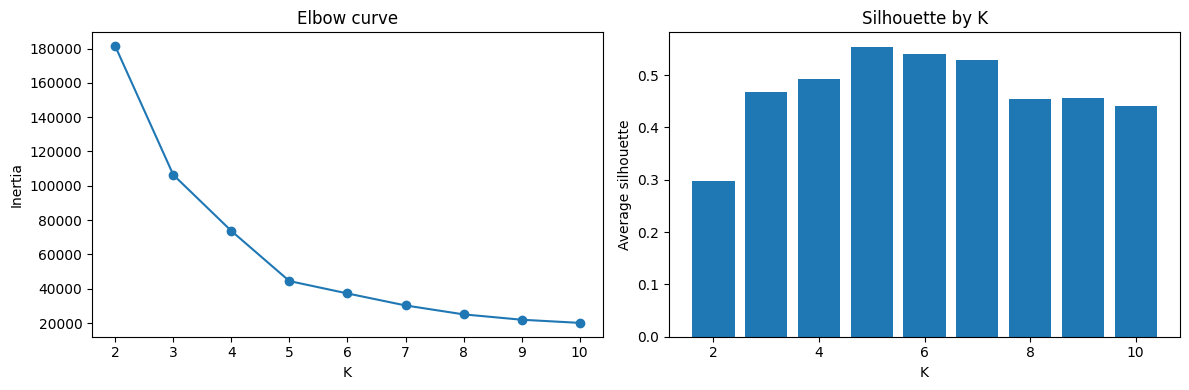

In [10]:
Ks = range(2, 11); inert, sil = [], []
for k in Ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X2)
    inert.append(km.inertia_); sil.append(silhouette_score(X2, km.labels_))
tab = pd.DataFrame({"K": list(Ks), "Inertia": np.round(inert, 1), "Silhouette": np.round(sil, 4)})
tab["Drop from previous K"] = tab["Inertia"].diff().round(1)
print(tab.to_string(index=False))
print("K with highest silhouette:", tab.loc[tab.Silhouette.idxmax(), "K"])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(list(Ks), inert, "o-"); ax[0].set_xlabel("K"); ax[0].set_ylabel("Inertia"); ax[0].set_title("Elbow curve")
ax[1].bar(list(Ks), sil); ax[1].set_xlabel("K"); ax[1].set_ylabel("Average silhouette"); ax[1].set_title("Silhouette by K")
plt.tight_layout(); plt.show()

**Interpretation.** Inertia falls from 181,364 at K=2 to 20,072 at K=10. The silhouette peaks at K=5 (0.5539) and falls after it.

### Task 2.2 — Silhouette by hand

In [11]:
km5 = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
L5 = km5.labels_
def sil_point(X, labels, i):
    D = np.sqrt(((X - X[i]) ** 2).sum(axis=1))
    own = labels == labels[i]
    a = D[own].sum() / (own.sum() - 1)            # exclude the point itself
    b = min(D[labels == c].mean() for c in np.unique(labels) if c != labels[i])
    return a, b, (b - a) / max(a, b)
a, b, s = sil_point(X2, L5, 0)
print(f"Customer 1 -> a={a:.4f}, b={b:.4f}, s={s:.4f}")
S = silhouette_samples(X2, L5)
print("sklearn silhouette_samples[0] =", round(S[0], 4))
print("Own cluster of customer 1:", L5[0])

Customer 1 -> a=24.6404, b=42.2653, s=0.4170
sklearn silhouette_samples[0] = 0.417
Own cluster of customer 1: 4


         Count    Mean     Min
Cluster                       
0           81  0.5967  0.1153
1           39  0.5092  0.2254
2           22  0.5990  0.0507
3           35  0.5040 -0.0234
4           23  0.5123 -0.0093
Customers with negative silhouette: 2


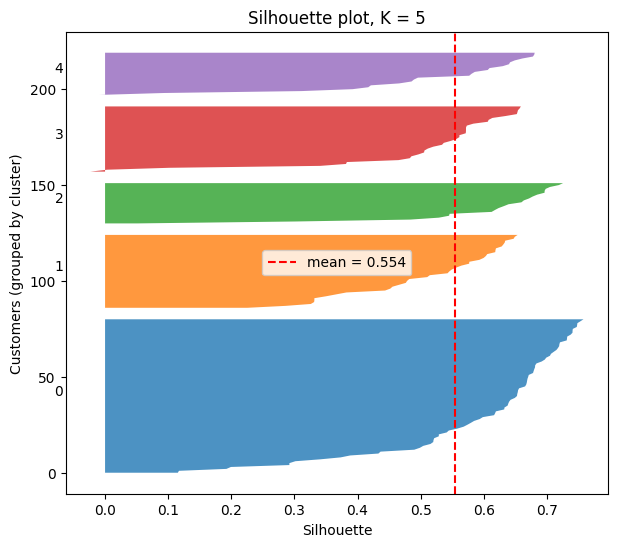

In [12]:
prof = pd.DataFrame({"Cluster": L5, "s": S}).groupby("Cluster")["s"].agg(Count="count", Mean="mean", Min="min").round(4)
print(prof)
print("Customers with negative silhouette:", int((S < 0).sum()))
fig, ax = plt.subplots(figsize=(7, 6)); y0 = 0
for c in range(5):
    sc = np.sort(S[L5 == c])
    ax.fill_betweenx(np.arange(y0, y0 + len(sc)), 0, sc, alpha=.8); ax.text(-0.08, y0 + len(sc)/2, str(c)); y0 += len(sc) + 5
ax.axvline(S.mean(), color="red", ls="--", label=f"mean = {S.mean():.3f}"); ax.set_xlabel("Silhouette"); ax.set_ylabel("Customers (grouped by cluster)")
ax.set_title("Silhouette plot, K = 5"); ax.legend(); plt.show()

**Interpretation.** My function matches sklearn for customer 1 (s = 0.4170). In the silhouette plot, most customers lie well to the right of 0; clusters 0 and 2 are the tightest (mean ≈ 0.60), while clusters 3 and 4 contain the only two negative values.

### Task 2.3 — The lecture practice problem

In [13]:
pp = np.array([1, 3, 5, 7, 11, 13, 15], dtype=float)
lp, Cp, inp, itp = my_kmeans(pp, [1, 11])
print("Clusters:", {k: pp[lp == k].tolist() for k in range(2)}, "| centroids:", Cp.ravel(), "| inertia:", inp, "| iterations:", itp)
Xp = pp[:, None]; Sp = silhouette_samples(Xp, lp)
rows = []
for v in [1, 7, 11]:
    i = int(np.where(pp == v)[0][0]); a, b, s = sil_point(Xp, lp, i)
    rows.append({"point": v, "a": round(a, 3), "b": round(b, 3), "s (mine)": round(s, 4), "s (sklearn)": round(Sp[i], 4)})
print(pd.DataFrame(rows).to_string(index=False))

Clusters: {0: [1.0, 3.0, 5.0, 7.0], 1: [11.0, 13.0, 15.0]} | centroids: [ 4. 13.] | inertia: 28.0 | iterations: 3
 point   a    b  s (mine)  s (sklearn)
     1 4.0 12.0    0.6667       0.6667
     7 4.0  6.0    0.3333       0.3333
    11 3.0  7.0    0.5714       0.5714


**Interpretation.** Final clusters {1,3,5,7} and {11,13,15}, centroids 4 and 13, inertia 28, found in 3 iterations (the last one confirms no change). a, b and s from my function equal `silhouette_samples` for points 1, 7 and 11. (Keep your own paper iterations for revision, as the manual says.)

**Questions**

**(a)** The elbow suggests **K=5**: the inertia drop from K=4 to 5 is 73,679.8 → 44,448.5 (−29,231, a 40% fall), while from K=5 to 6 it is only −7,215 (16%) and later drops are even smaller. The silhouette is highest at **K=5 (0.5539)**, with K=6 at 0.5398. They agree on 5.

**(b)** Customer 1: a = 24.64, b = 42.27, s = **0.417**. It is clearly nearer its own cluster (cluster 4, low income / low spending) than to the next one, but with a moderate value, because that cluster is fairly spread out. The weakest average silhouette is **cluster 3** (35 customers, mean 0.504); **2 customers** have a negative silhouette (one in cluster 3, min −0.023; one in cluster 4, min −0.009), both essentially on the border.

**(c)** **Point 7** is less well placed: a = 4, b = 6, s = 0.333, since it is only 2 units closer on average to its own cluster than to the other. Point 1 has a = 4, b = 12, s = 0.667 (clearly inside its cluster).

**(d)** Inertia always decreases as K grows (it reaches 0 when K = number of points), so the lowest inertia would always pick the largest K and give useless clusters. K must be chosen at the bend of the curve, together with the silhouette and interpretability.

## Part 3 — Starting Points and Stability

### Task 3.1 — 30 different seeds

             Setting  Distinct inertias  Lowest  Highest  % runs at best
    random, n_init=1                 14 44448.5  91762.0            33.3
 k-means++, n_init=1                  6 44448.5  66733.4            60.0
k-means++, n_init=10                  1 44448.5  44448.5           100.0
Global best inertia: 44448.5


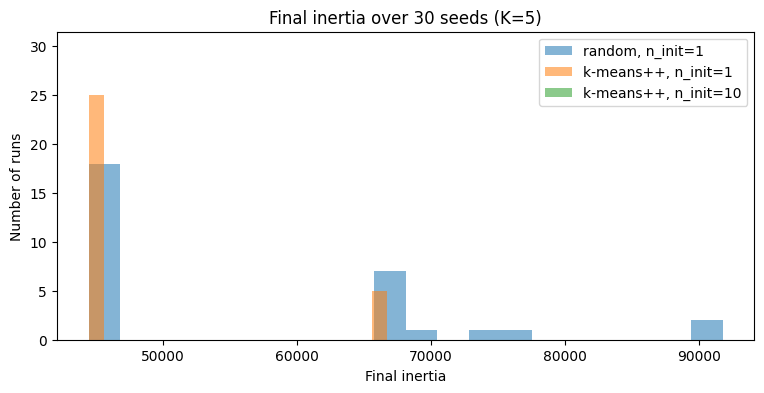

In [14]:
settings = {"random, n_init=1": dict(init="random", n_init=1),
            "k-means++, n_init=1": dict(init="k-means++", n_init=1),
            "k-means++, n_init=10": dict(init="k-means++", n_init=10)}
res = {n: [KMeans(n_clusters=5, random_state=s, **kw).fit(X2) for s in range(30)] for n, kw in settings.items()}
best = min(m.inertia_ for r in res.values() for m in r)
rows = []
for n, r in res.items():
    v = np.array([m.inertia_ for m in r])
    rows.append({"Setting": n, "Distinct inertias": len(np.unique(v.round(1))), "Lowest": v.min().round(1),
                 "Highest": v.max().round(1), "% runs at best": round(100 * np.mean(np.isclose(v, best, atol=0.1)), 1)})
print(pd.DataFrame(rows).to_string(index=False)); print("Global best inertia:", round(best, 1))
plt.figure(figsize=(9, 4))
for n, r in res.items(): plt.hist([m.inertia_ for m in r], bins=20, alpha=.55, label=n)
plt.xlabel("Final inertia"); plt.ylabel("Number of runs"); plt.title("Final inertia over 30 seeds (K=5)"); plt.legend(); plt.show()

**Interpretation.** Random starts often end in worse local minima; k-means++ is more reliable; k-means++ with 10 restarts always hits the best solution.

### Task 3.2 — Best run vs worst run

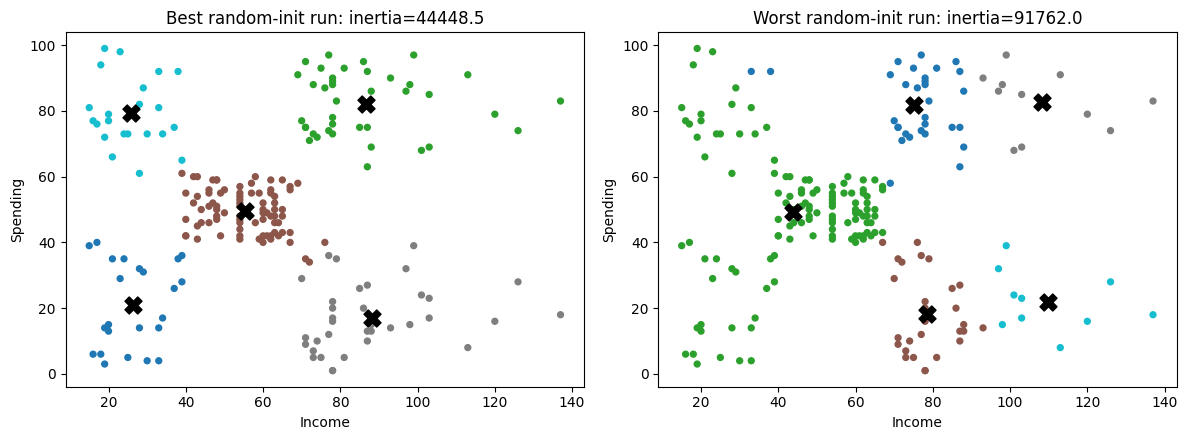

Best inertia: 44448.5 | worst inertia: 91762.0 | ARI between them: 0.4553


In [15]:
rr = res["random, n_init=1"]
bst = min(rr, key=lambda m: m.inertia_); wst = max(rr, key=lambda m: m.inertia_)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for a, m, t in zip(ax, [bst, wst], ["Best random-init run", "Worst random-init run"]):
    a.scatter(X2[:, 0], X2[:, 1], c=m.labels_, cmap="tab10", s=18)
    a.scatter(*m.cluster_centers_.T, c="k", marker="X", s=150); a.set_title(f"{t}: inertia={m.inertia_:.1f}"); a.set_xlabel("Income"); a.set_ylabel("Spending")
plt.tight_layout(); plt.show()
print("Best inertia:", round(bst.inertia_, 1), "| worst inertia:", round(wst.inertia_, 1), "| ARI between them:", round(adjusted_rand_score(bst.labels_, wst.labels_), 4))

**Interpretation.** The best run has inertia 44,448.5 (the five natural groups); the worst has 91,762.0 (about twice as high), so several centroids ended up in poor positions. Look at the right panel to see which groups were merged or split. ARI between them is only 0.4553.

**Questions**

**(a)** Random starts (n_init=1) produced **14** different final inertia values, and only **33.3%** of the 30 runs reached the best (44,448.5). k-means++ with n_init=1 produced 6 values, 60% best. k-means++ with n_init=10 produced **1** value, 100% best.

**(b)** K-Means only finds a local minimum, which depends on where the centroids start. Different starting centroids lead the assign/update loop to different stable partitions.

**(c)** k-means++ spreads the starting centroids far apart, so there are fewer bad starts (60% vs 33.3% good runs). `n_init=10` runs 10 different starts and keeps the one with the lowest inertia; in my table that gave the best inertia in all 30 of 30 seeds (100%).

**(d)** Cluster numbers are arbitrary: the same grouping can be labelled (0,1,2) in one run and (2,0,1) in another. ARI compares which points are grouped together, ignoring the label names.

## Part 4 — Scaling: Units Decide the Clusters

### Task 4.1 — Change the unit, change the clusters

ARI raw k$ vs raw dollars      : 0.4897
ARI scaled k$ vs scaled dollars: 1.0
ARI raw dollars vs scaled      : 0.3605
ARI raw k$ vs scaled           : 0.7701


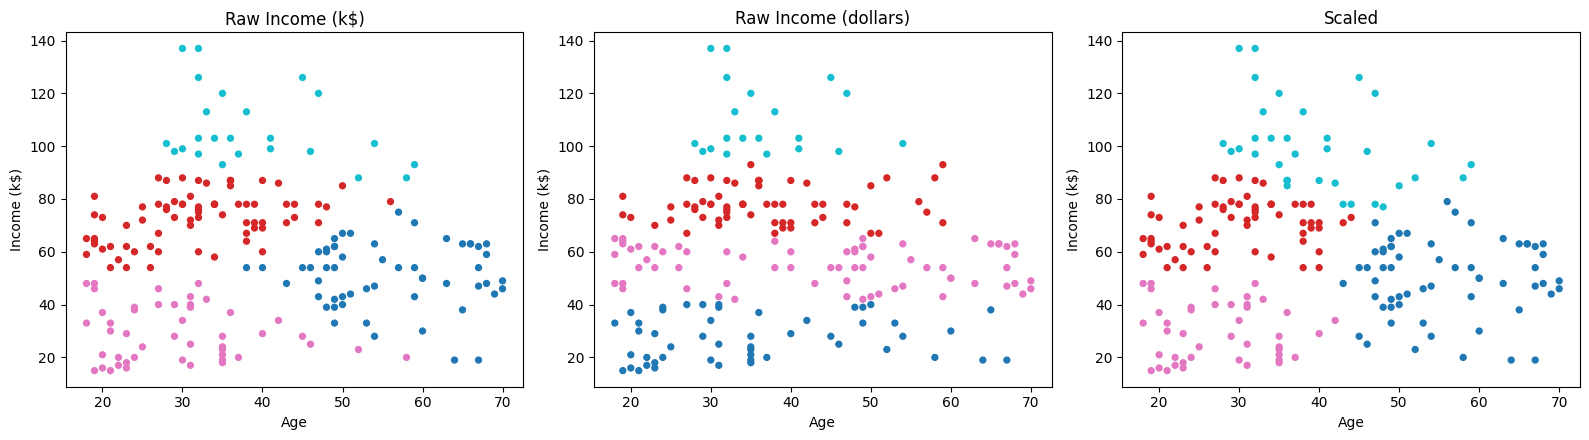

In [16]:
A_k = df[["Age", "Income"]].values.astype(float)
A_d = A_k.copy(); A_d[:, 1] *= 1000
def fit4(X, scale):
    X = StandardScaler().fit_transform(X) if scale else X
    return KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(X).labels_
l_rk, l_rd, l_sk, l_sd = fit4(A_k, 0), fit4(A_d, 0), fit4(A_k, 1), fit4(A_d, 1)
print("ARI raw k$ vs raw dollars      :", round(adjusted_rand_score(l_rk, l_rd), 4))
print("ARI scaled k$ vs scaled dollars:", round(adjusted_rand_score(l_sk, l_sd), 4))
print("ARI raw dollars vs scaled      :", round(adjusted_rand_score(l_rd, l_sk), 4))
print("ARI raw k$ vs scaled           :", round(adjusted_rand_score(l_rk, l_sk), 4))
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, l, t in zip(ax, [l_rk, l_rd, l_sk], ["Raw Income (k$)", "Raw Income (dollars)", "Scaled"]):
    a.scatter(A_k[:, 0], A_k[:, 1], c=l, cmap="tab10", s=18); a.set_xlabel("Age"); a.set_ylabel("Income (k$)"); a.set_title(t)
plt.tight_layout(); plt.show()

**Interpretation.** Merely multiplying Income by 1000 changed the raw clustering (ARI 0.4897 between k$ and dollars), whereas after scaling the result is identical (ARI 1.0). In the raw-dollars plot the clusters are horizontal Income bands, so Age has almost no say.

### Task 4.2 — Wine data: raw vs scaled

In [17]:
wine = load_wine(); Xw, yw = wine.data, wine.target
sd = pd.Series(Xw.std(axis=0), index=wine.feature_names).sort_values(ascending=False)
print("Three largest std:"); print(sd.head(3).round(3)); print("Smallest std:"); print(sd.tail(1).round(4))

Three largest std:
proline              314.022
magnesium             14.242
alcalinity_of_ash      3.330
dtype: float64
Smallest std:
nonflavanoid_phenols    0.1241
dtype: float64


In [18]:
Xw_s = StandardScaler().fit_transform(Xw)
out = {}
for name, Xin in [("raw", Xw), ("scaled", Xw_s)]:
    km = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(Xin)
    out[name] = km.labels_
    print(f"{name:7s} ARI vs cultivar={adjusted_rand_score(yw, km.labels_):.4f}  silhouette={silhouette_score(Xin, km.labels_):.4f}  sizes={np.bincount(km.labels_).tolist()}")

raw     ARI vs cultivar=0.3711  silhouette=0.5711  sizes=[62, 47, 69]
scaled  ARI vs cultivar=0.8975  silhouette=0.2849  sizes=[65, 51, 62]


### Task 4.3 — Draw it

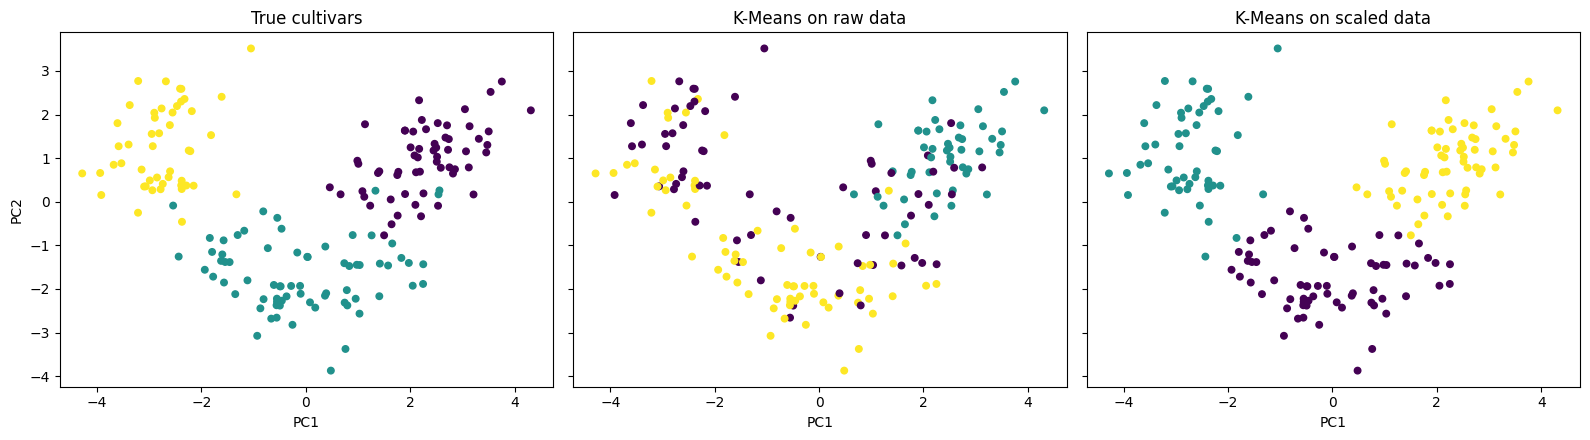

In [19]:
Z = PCA(n_components=2, random_state=SEED).fit_transform(Xw_s)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True, sharey=True)
for a, l, t in zip(ax, [yw, out["raw"], out["scaled"]], ["True cultivars", "K-Means on raw data", "K-Means on scaled data"]):
    a.scatter(Z[:, 0], Z[:, 1], c=l, cmap="viridis", s=22); a.set_title(t); a.set_xlabel("PC1")
ax[0].set_ylabel("PC2"); plt.tight_layout(); plt.show()

**Interpretation.** With scaling, the three clusters line up closely with the three true cultivars in the PCA plane; on raw data the clusters do not follow the cultivars (ARI only 0.3711), because proline alone drives the distance. Compare the middle and right panels with the left one to see where the raw clusters disagree.

**Questions**

**(a)** The distance is sqrt(ΔAge² + ΔIncome²). In k$, Income differences (range ≈ 122) are only ~2× bigger than Age (range 52), so both matter. In dollars, Income differences are 1000× bigger (range 122,000), so distance is almost entirely Income and Age becomes irrelevant. Same customers, different clusters: raw k$ vs raw dollars ARI = 0.4897; raw dollars vs scaled = 0.3605; scaled k$ vs scaled dollars = 1.0.

**(b)** **Proline** dominated, with std 314.0, versus 14.2 for magnesium, 3.3 for alcalinity of ash and 0.124 for the smallest (nonflavanoid phenols): about 2,500× larger than the smallest. ARI against the true cultivar: **0.3711 raw vs 0.8975 scaled**.

**(c)** Silhouette is computed with the same distances as K-Means. On raw data, one feature (proline) dominates the geometry, so the points really are well separated along that one axis and the silhouette is high (0.5711), but the grouping reflects proline only, not the cultivars. After scaling, all 13 features contribute, and the groups overlap more in 13-D, so silhouette is lower (0.2849) although the clustering is far better (ARI 0.8975). Silhouettes from different feature spaces/scales are therefore not comparable.

**(d)** My rule: scale whenever features have different units or very different ranges (std ratios of 10× or more), unless a feature's raw size is deliberately meant to carry importance. Then check that the chosen features and clusters make business sense, as a check that no single feature dominates.

## Part 5 — Outliers and Anomalies

### Task 5.1 — One extreme customer

In [20]:
X2e = np.vstack([X2, [400, 99]])
km_o = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
km_e = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2e)
def show(km, name):
    o = np.argsort(km.cluster_centers_[:, 0])
    print(name, "- sizes (sorted by centroid income):", np.bincount(km.labels_)[o].tolist())
    print(km.cluster_centers_[o].round(1))
show(km_o, "Original 200"); show(km_e, "With extra customer (201)")
print("ARI on the original 200 customers:", round(adjusted_rand_score(km_o.labels_, km_e.labels_[:200]), 4))

Original 200 - sizes (sorted by centroid income): [22, 23, 81, 39, 35]
[[25.7 79.4]
 [26.3 20.9]
 [55.3 49.5]
 [86.5 82.1]
 [88.2 17.1]]
With extra customer (201) - sizes (sorted by centroid income): [23, 100, 39, 38, 1]
[[ 26.3  20.9]
 [ 48.3  56.5]
 [ 86.5  82.1]
 [ 87.   18.6]
 [400.   99. ]]
ARI on the original 200 customers: 0.7532


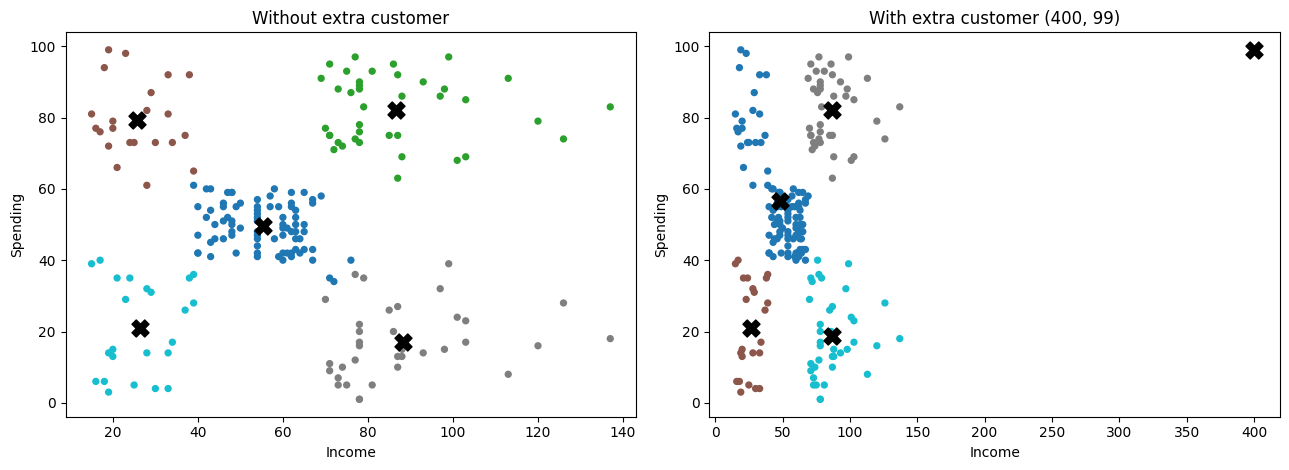

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ax[0].scatter(*X2.T, c=km_o.labels_, cmap="tab10", s=18); ax[0].scatter(*km_o.cluster_centers_.T, c="k", marker="X", s=150); ax[0].set_title("Without extra customer")
ax[1].scatter(*X2e.T, c=km_e.labels_, cmap="tab10", s=18); ax[1].scatter(*km_e.cluster_centers_.T, c="k", marker="X", s=150); ax[1].set_title("With extra customer (400, 99)")
for a in ax: a.set_xlabel("Income"); a.set_ylabel("Spending")
plt.tight_layout(); plt.show()

**Interpretation.** One customer at (400, 99) gets its own cluster (size 1). To pay for that, the other four centroids have to cover 200 points, so two real groups are merged.

### Task 5.2 — Catch it and repair

In [22]:
dist = km_o.transform(X2).min(axis=1)
d_extra = km_o.transform([[400, 99]]).min()
thr = dist.mean() + 3 * dist.std()
flag = dist > thr
print(f"mean={dist.mean():.2f}, std={dist.std():.2f}, threshold={thr:.2f}")
print("Real customers flagged:", int(flag.sum()), "| extra customer distance:", round(d_extra, 1), "-> flagged:", bool(d_extra > thr))
top = df.assign(Cluster=km_o.labels_, Distance=dist.round(2)).sort_values("Distance", ascending=False).head(5)
print(top[["CustomerID", "Age", "Income", "Spending", "Cluster", "Distance"]].to_string(index=False))
keep = ~flag
km_r = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2[keep])
print("Refit sizes (kept points):", np.bincount(km_r.labels_).tolist())
print("ARI vs original model on all 200 customers (predict):", round(adjusted_rand_score(km_o.labels_, km_r.predict(X2)), 4))

mean=13.02, std=7.26, threshold=34.80
Real customers flagged: 4 | extra customer distance: 313.9 -> flagged: True
 CustomerID  Age  Income  Spending  Cluster  Distance
        200   30     137        83        1     50.47
        199   32     137        18        3     48.81
        198   32     126        74        1     40.29
        197   45     126        28        3     39.34
        196   35     120        79        1     33.61
Refit sizes (kept points): [80, 34, 23, 37, 22]
ARI vs original model on all 200 customers (predict): 0.9847


**Interpretation.** The extra customer is 313.9 from its nearest centroid, far above the threshold of 34.80 (mean 13.02 + 3 × std 7.26).

**Questions**

**(a)** The single point took one whole cluster (size 1, centroid (400, 99)). The sizes changed from [22, 23, 81, 39, 35] to [23, 100, 39, 38, 1]: the *low-income / high-spending* group (22 customers, centroid ≈ (25.7, 79.4)) and the *mid / mid* group (81) were merged into one cluster of 100 with centroid (48.3, 56.5), and the *high-income / low-spending* group grew from 35 to 38. ARI on the original 200 customers fell to 0.7532.

**(b)** The rule flagged the extra customer clearly (313.9 vs threshold 34.8) and also **4 real customers**: IDs 200, 199, 198, 197. They have Incomes of 137, 137, 126 and 126 (k$), the highest in the dataset, and Spending of 83, 18, 74 and 28. They are not data errors; they are valid but extreme rich customers on the edge of the high-income groups, worth looking at (e.g. a VIP offer). After removing the 4 flagged points the refit gives sizes [80, 34, 23, 37, 22] and ARI 0.9847 against the original model: practically the same groups.

**(c)** Two ways: check/correct or cap (winsorize) the extreme values; use a more robust method (K-Medoids or DBSCAN) or a transformation (log) that reduces the pull of extremes; or cluster the main body and treat outliers as a separate segment. Risk of deleting: you may remove genuine, high-value customers (as the 4 flagged ones are) and the model then says nothing about them.

## Part 6 — From Clusters to Customer Segments

### Task 6.1 — Profile and name the segments

In [23]:
df["Cluster"] = km_o.labels_
df["Female"] = (df["Gender"] == "Female").astype(int)
profile = (df.groupby("Cluster").agg(Customers=("Age", "size"), Age=("Age", "mean"), Income=("Income", "mean"),
           Spending=("Spending", "mean"), Pct_female=("Female", lambda s: 100 * s.mean())).round(1).sort_values("Income"))
profile

,Customers,Age,Income,Spending,Pct_female
Cluster,,,,,
2,22,25.3,25.7,79.4,59.1
4,23,45.2,26.3,20.9,60.9
0,81,42.7,55.3,49.5,59.3
1,39,32.7,86.5,82.1,53.8
3,35,41.1,88.2,17.1,45.7


In [24]:
def lvl(v, lo, hi): return "Low" if v < lo else ("High" if v >= hi else "Mid")
names = {c: f"{lvl(r.Income, 40, 70)} income / {lvl(r.Spending, 35, 65)} spending" for c, r in profile.iterrows()}
df["Segment"] = df["Cluster"].map(names)
print(df["Segment"].value_counts())
profile.assign(Segment=profile.index.map(names))

Segment
Mid income / Mid spending      81
High income / High spending    39
High income / Low spending     35
Low income / Low spending      23
Low income / High spending     22
Name: count, dtype: int64


,Customers,Age,Income,Spending,Pct_female,Segment
Cluster,,,,,,
2,22,25.3,25.7,79.4,59.1,Low income / High spending
4,23,45.2,26.3,20.9,60.9,Low income / Low spending
0,81,42.7,55.3,49.5,59.3,Mid income / Mid spending
1,39,32.7,86.5,82.1,53.8,High income / High spending
3,35,41.1,88.2,17.1,45.7,High income / Low spending


**Interpretation.** The five clusters map to five clean segment names with no duplicates, so the naming rule is consistent with the clustering.

### Task 6.2 — Does Gender matter? Does Age matter?

In [25]:
print("Overall % female:", round(100 * df["Female"].mean(), 1))
print(df.groupby("Segment")["Female"].mean().mul(100).round(1).rename("% female"))
X3 = StandardScaler().fit_transform(df[["Age", "Income", "Spending"]])
sil3 = {k: round(silhouette_score(X3, KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X3)), 4) for k in range(2, 9)}
print(pd.Series(sil3, name="silhouette (Age, Income, Spending scaled)"))

Overall % female: 56.0
Segment
High income / High spending    53.8
High income / Low spending     45.7
Low income / High spending     59.1
Low income / Low spending      60.9
Mid income / Mid spending      59.3
Name: % female, dtype: float64
2    0.3355
3    0.3578
4    0.4040
5    0.4166
6    0.4284
7    0.4172
8    0.4082
Name: silhouette (Age, Income, Spending scaled), dtype: float64


**Interpretation.** Women are 56.0% overall and between 45.7% and 60.9% in the segments. For three features, the silhouette is highest at K=6 (0.4284), K=5 = 0.4166.

### Task 6.3 — A three-feature alternative

In [26]:
bestK = max(sil3, key=sil3.get); print("Best K:", bestK)
km3 = KMeans(n_clusters=bestK, n_init=10, random_state=SEED).fit(X3)
df["Cluster3"] = km3.labels_
prof3 = df.groupby("Cluster3").agg(Customers=("Age", "size"), Age=("Age", "mean"), Income=("Income", "mean"), Spending=("Spending", "mean")).round(1).sort_values("Age")
print(prof3)
print("ARI (3-feature vs 2-feature K=5):", round(adjusted_rand_score(df["Cluster"], df["Cluster3"]), 4))

Best K: 6
          Customers   Age  Income  Spending
Cluster3                                   
4                23  25.0    25.3      77.6
1                39  26.8    57.1      48.1
3                39  32.7    86.5      82.1
2                33  41.9    88.9      17.0
5                21  45.5    26.3      19.4
0                45  56.3    54.3      49.1
ARI (3-feature vs 2-feature K=5): 0.7002


**Interpretation.** With Age added, K=6: the big mid/mid group splits by age into 39 younger (avg age 26.8) and 45 older (avg age 56.3) customers; the other groups stay about the same. ARI against the 2-feature K=5 result is 0.7002.

**Questions**

**(a)** (Names and actions based on my profile table.)
- **Low income / High spending** (22 customers, age 25, income 25.7k, spending 79.4): young trend-followers → low-cost, trend/fashion offers, student/youth deals.
- **Low income / Low spending** (23, age 45, income 26.3k, spending 20.9): price-sensitive → discount coupons, value bundles.
- **Mid / Mid** (81, age 43, income 55.3k, spending 49.5): the average customers → loyalty points and cross-selling to nudge them up.
- **High income / High spending** (39, age 33, income 86.5k, spending 82.1): VIPs → loyalty tier, early access, premium services.
- **High income / Low spending** (35, age 41, income 88.2k, spending 17.1): wealthy but inactive → premium/personalised invitations, find out what they are missing.

**(b)** Most valuable now: **High income / High spending** (39 customers; 86.5k income and the highest spend, 82.1). Biggest opportunity: **High income / Low spending** (35 customers, income 88.2k but spend only 17.1): they could afford much more, so even a modest rise in their spending is worth more than for the low-income groups. (This is a judgement: Spending Score is the mall's own metric and I do not have revenue data.)

**(c)** Not really. Women: 56.0% overall; by segment 53.8%, 45.7%, 59.1%, 60.9% and 59.3%. The biggest difference (45.7% in the high-income / low-spending group) is about 10 points, on a group of 35, i.e. only a few customers, so gender does not separate the segments.

**(d)** Age adds a bit of detail (the mid group splits into 26.8 vs 56.3 years), but the Income–Spending structure stays the same (ARI 0.70). I would present the **2-feature K = 5** segmentation as the main result (clear five-block structure, highest silhouette 0.5539 on its own feature space, simple actions), and mention the age split of the mid group as a possible refinement. The silhouettes (0.5539 vs 0.4284) must not be compared, since they are computed on different features.

## Part 7 — Final Output and Wrap-Up

### Task 7.1 — Save the segments

In [27]:
out_df = df[["CustomerID", "Age", "Gender", "Income", "Spending", "Cluster", "Segment"]]
out_df.to_csv("customer_segments.csv", index=False)
print(out_df["Segment"].value_counts()); out_df.head()

Segment
Mid income / Mid spending      81
High income / High spending    39
High income / Low spending     35
Low income / Low spending      23
Low income / High spending     22
Name: count, dtype: int64


,CustomerID,Age,Gender,Income,Spending,Cluster,Segment
0,1,19,Male,15,39,4,Low income / Low spending
1,2,21,Male,15,81,2,Low income / High spending
2,3,20,Female,16,6,4,Low income / Low spending
3,4,23,Female,16,77,2,Low income / High spending
4,5,31,Female,17,40,4,Low income / Low spending


**Executive Summary**

I segmented the 200 Mall customers with K-Means on Income and Spending, choosing **K = 5**: the elbow flattens after K=5 (inertia −29,231 from K=4 to 5, only −7,215 from 5 to 6) and the silhouette peaks there (0.5539). The segments are Mid/Mid (81 customers), High/High (39), High income/Low spending (35), Low/Low (23) and Low income/High spending (22). Suggested actions: VIP loyalty for High/High, personalised premium offers for the high-income low spenders, loyalty points for the mid group, trend deals for the young low-income high spenders, and discounts for the Low/Low group. Both features are in similar units, and Part 4 showed that features with different scales must be scaled; I used `n_init=10`, because single random starts reached the best solution in only 33% of runs. One extreme customer (400k$) was shown to destroy the structure, and the 3-std distance rule found it plus 4 real high-income customers, which I kept. A limitation: the data is only 200 customers with 2 features and a mall-defined Spending Score, so the segments describe behaviour, not revenue or causes. Results are saved in `customer_segments.csv`.

**Questions**

**(a)** The biggest surprise was that changing only the unit of Income (k$ → dollars) changed the clusters (ARI 0.49) and that the Wine silhouette was higher for the *worse* raw clustering (0.5711 vs 0.2849).

**(b)** With one more hour: compare with K-Medoids/DBSCAN or a Gaussian mixture, add real revenue data to value each segment, and test whether the segments stay stable over time/bootstrap samples.